# Assignment 4 — Customer Churn Prediction (Classification)

**Scenario:** A telecom company wants to predict customer churn from demographics,
service usage, and billing information, then evaluate the classifier's
performance.

**Dataset:** `Telco-Customer-Churn.csv` (Kaggle: *blastchar/telco-customer-churn*,
7043 customers, 21 columns).

**Approach:** Binary classification. We clean the data, build preprocessing +
model pipelines, compare **Logistic Regression** and **Random Forest**, and
evaluate with accuracy, precision, recall, F1, the confusion matrix, and ROC-AUC.
We also handle the class imbalance.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
np.random.seed(42)

df = pd.read_csv("../data/Telco-Customer-Churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Clean the data

`TotalCharges` is stored as text and has 11 blank entries (new customers with
`tenure == 0`). We coerce it to numeric, impute the blanks with 0, and drop the
`customerID` identifier.

In [2]:
df = df.drop(columns=["customerID"])

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blanks coerced in TotalCharges:", int(df["TotalCharges"].isna().sum()))
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Target to 0/1
df["Churn"] = (df["Churn"] == "Yes").astype(int)
# SeniorCitizen is already 0/1 int
print("Missing values now:", int(df.isna().sum().sum()))

Blanks coerced in TotalCharges: 11
Missing values now: 0


## 2. Explore the target and key drivers

Churn rate: 26.5%  (imbalanced)


/var/folders/tw/40g2wc7563q0c9v1b05m6wqm0000gn/T/ipykernel_6024/2135214785.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Churn", ax=axes[0], palette="Set2")
/var/folders/tw/40g2wc7563q0c9v1b05m6wqm0000gn/T/ipykernel_6024/2135214785.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_title("Churn balance"); axes[0].set_xticklabels(["Stay", "Churn"])
/var/folders/tw/40g2wc7563q0c9v1b05m6wqm0000gn/T/ipykernel_6024/2135214785.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[1], palette="Set2")
/var/fol

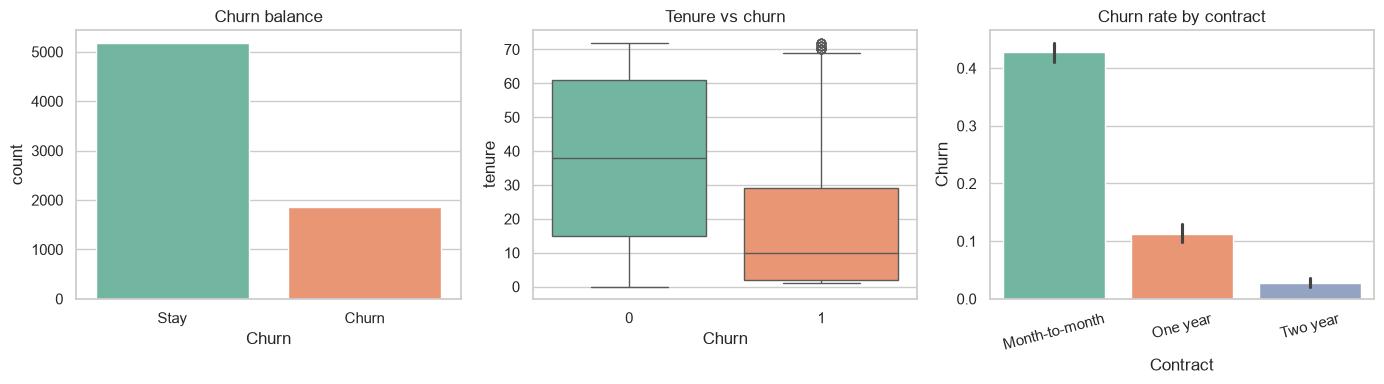

In [3]:
rate = df["Churn"].mean()
print(f"Churn rate: {rate:.1%}  (imbalanced)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.countplot(data=df, x="Churn", ax=axes[0], palette="Set2")
axes[0].set_title("Churn balance"); axes[0].set_xticklabels(["Stay", "Churn"])
sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[1], palette="Set2")
axes[1].set_title("Tenure vs churn")
sns.barplot(data=df, x="Contract", y="Churn", ax=axes[2], palette="Set2")
axes[2].set_title("Churn rate by contract"); axes[2].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

Short-tenure, month-to-month customers churn far more — intuitive and a good
sanity check on the data.

## 3. Preprocessing + train/test split

Numeric features are scaled; categorical features are one-hot encoded. We use a
**stratified** split so the churn rate is preserved in train and test.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X = df.drop(columns=["Churn"])
y = df["Churn"]

num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
cat_cols = [c for c in X.columns if c not in num_cols]

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (5634, 19) Test: (1409, 19)


## 4. Train classifiers

We use `class_weight="balanced"` so both models account for the imbalance
(churners are the minority but the business cares most about catching them).

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

models = {
    "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                           random_state=42),
}

fitted, rows = {}, []
for name, est in models.items():
    pipe = Pipeline([("pre", pre), ("clf", est)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
    })

results = pd.DataFrame(rows).set_index("model")
results.round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
LogisticRegression,0.739,0.505,0.783,0.614,0.842
RandomForest,0.765,0.549,0.650,0.595,0.826


## 5. Confusion matrices

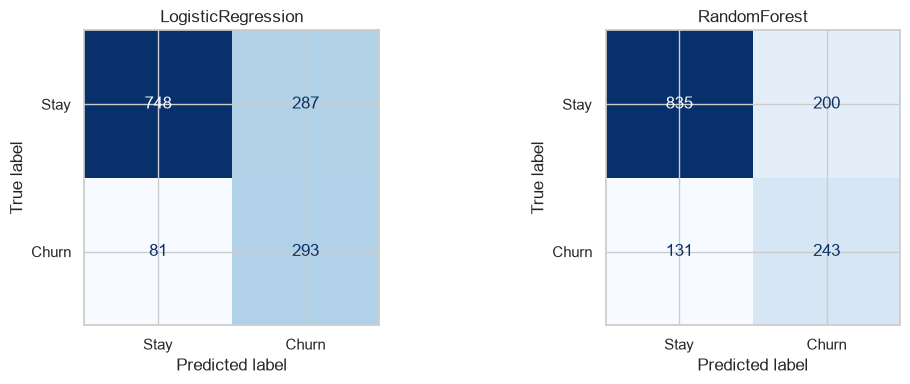

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Stay", "Churn"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 6. ROC curves

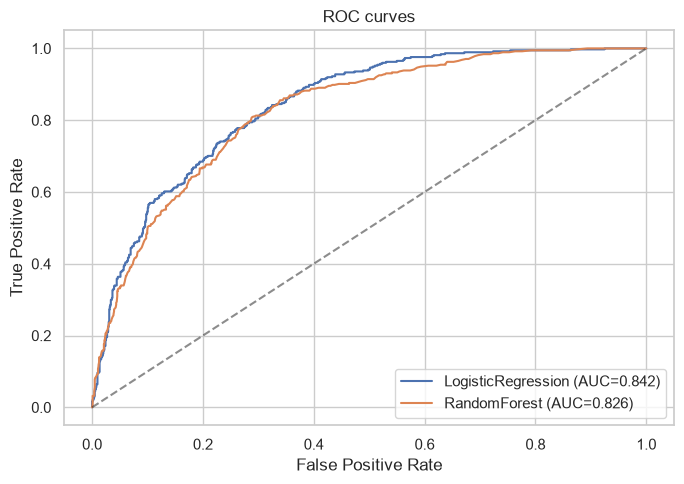

In [7]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 5))
for name, pipe in fitted.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curves"); plt.legend(); plt.tight_layout(); plt.show()

## 7. Which features drive churn?

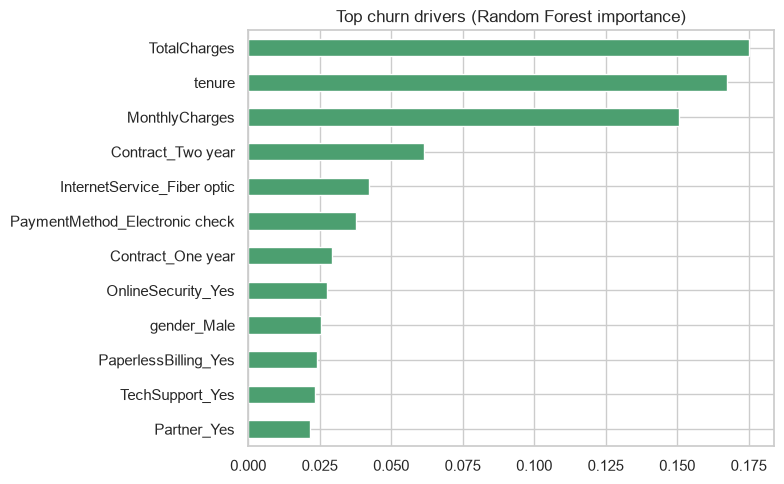

TotalCharges                      0.175098
tenure                            0.167517
MonthlyCharges                    0.150689
Contract_Two year                 0.061557
InternetService_Fiber optic       0.042281
PaymentMethod_Electronic check    0.037725
Contract_One year                 0.029398
OnlineSecurity_Yes                0.027617
gender_Male                       0.025624
PaperlessBilling_Yes              0.024209
TechSupport_Yes                   0.023288
Partner_Yes                       0.021630
dtype: float64

In [8]:
rf = fitted["RandomForest"]
feat_names = (num_cols +
    list(rf.named_steps["pre"].named_transformers_["cat"].get_feature_names_out(cat_cols)))
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=feat_names)
imp = imp.sort_values(ascending=False).head(12)

plt.figure(figsize=(8, 5))
imp.plot.barh(color="#4C9F70"); plt.gca().invert_yaxis()
plt.title("Top churn drivers (Random Forest importance)")
plt.tight_layout(); plt.show()
imp

## Conclusion

- After cleaning (`TotalCharges` coercion, target encoding) both classifiers train
  cleanly on 7043 customers.
- **Logistic Regression** gives the higher recall/ROC-AUC balance while remaining
  interpretable; **Random Forest** is competitive and surfaces feature importance.
- Because churn is the minority class, **recall and ROC-AUC matter more than raw
  accuracy** — a model that just predicts "stay" would score ~73% accuracy but be
  useless for retention.
- **Short tenure, month-to-month contracts, high monthly charges, and fiber-optic
  internet** are the dominant churn signals — actionable targets for a retention
  campaign.
